# LifeGuard-RL XJTU digital twin validation

Forecast the future SOH and remaining useful life (RUL) of an unseen cell under its recorded fixed charging protocol. Start at cycle 50 or 100 and compare an SOH-dependent model with the same model adjusted using recent charging history.

1. On **Kaggle CPU**, attach the same SOH data and **XJTU_labels.json** used for notebook 06. Attach **lifeguard_rul_charge_features_results.zip** or its exported **rul_predictions.csv** to compare with the saved RUL estimates.
2. Run all cells. The same five XJTU cell splits are used. Cycle 100 is the primary comparison.
3. Download **lifeguard_digital_twin_validation_results.zip** with held-out forecasts, model calibration, errors, and an example trajectory plot.

[BatteryLife v12 release](https://zenodo.org/records/21149533)

In [82]:
INPUT_ROOT = None
SOH_RESULTS_PATH = None  # Set to a SOH ZIP or extracted folder if needed.
LABEL_PATH = None  # Optional explicit XJTU label JSON.
RUL_RESULTS_PATH = None  # Optional explicit notebook 06 ZIP, folder, or CSV.
OUTPUT_ROOT = None
SEED = 42

from collections import deque
from importlib.metadata import version
import json
from pathlib import Path, PurePosixPath
from tempfile import TemporaryDirectory
from zipfile import ZIP_DEFLATED, ZipFile

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits

if INPUT_ROOT is None:
    if Path("/kaggle/input").is_dir():
        INPUT_ROOT = "/kaggle/input"
    elif Path.cwd().name == "notebooks":
        INPUT_ROOT = Path.cwd().parent
    else:
        INPUT_ROOT = Path.cwd()
if OUTPUT_ROOT is None:
    OUTPUT_ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd() / "outputs"
INPUT_ROOT = Path(INPUT_ROOT).expanduser().resolve()
OUTPUT_ROOT = Path(OUTPUT_ROOT).expanduser().resolve()
if not INPUT_ROOT.is_dir():
    raise FileNotFoundError(f"Input folder does not exist: {INPUT_ROOT}")

## Calibration and forecasts

Every fold fits the charge-only SOH estimator and the degradation rates on its training cells. The simulator stays on the recorded 2C or 3C rate. At each charge rate, use observed SOH loss across up to ten cycles after cycle 50. Give each training cell equal weight within each two-point SOH bin. The simulator interpolates the rates between supported bins and records steps outside those bins.

The history-adjusted model estimates the recent fade rate from the first and last five usable charge estimates in the last twenty cycles. It shrinks the resulting multiplier toward one. An unsupported rate or insufficient trend history uses the group rate. The two initialization modes use the same charge history, allowing a comparison of measured versus estimated starting SOH.

One-, ten-, and fifty-cycle SOH errors are evaluated against the still-observed part of each test trace. After the simulated 80% crossing, the trajectory holds at 80% for the remaining horizon comparison. The RUL comparison uses verified EOL labels. The 2C reference is the prior protocol median at both landmarks. The 3C reference is the prior recent-signals Ridge at 50 and the original pooled Ridge at 100.

In [83]:
KEY = ["cell_id", "cycle"]
FIXED_CELLS = {
    f"XJTU_{rate}C_battery-{number}": rate
    for rate, count in ((2, 8), (3, 15))
    for number in range(1, count + 1)
}
NOMINAL_AH = 2.0
HISTORY_SIZE = 10
MIN_FLAG_HISTORY = 5
MAD_MULTIPLIER = 6.0
FLAG_FLOORS = {"prefix_charge_ah": 0.08, "charge_duration_s": 120.0, "taper_duration_s": 120.0}
CHARGE_FIELDS = [*FLAG_FLOORS, "taper_charge_ah"]
RESULT_ARCHIVES = ("lifeguard_soh_validation_results.zip", "lifeguard_soh_results.zip")


def one_match(matches, description):
    matches = sorted(set(matches))
    if len(matches) != 1:
        raise ValueError(f"Expected one {description}, found {len(matches)}. Set SOH_RESULTS_PATH.")
    return matches[0]


def locate_soh_export(root):
    if SOH_RESULTS_PATH is not None:
        return Path(SOH_RESULTS_PATH).expanduser().resolve()
    for filename in RESULT_ARCHIVES:
        matches = list(root.rglob(filename))
        if matches:
            return one_match(matches, filename)
    folders = [p.parent for p in root.rglob("cycle_quality.csv") if (p.parent / "cycle_features.csv").is_file()]
    return one_match(folders, "folder with both cycle tables")


def load_cycles(source):
    names = ("cycle_quality.csv", "cycle_features.csv")
    if source.is_dir():
        quality, features = (pd.read_csv(source / name) for name in names)
    else:
        with ZipFile(source) as archive:
            tables = []
            for name in names:
                member = one_match([member for member in archive.namelist() if PurePosixPath(member).name == name], name)
                with archive.open(member) as stream:
                    tables.append(pd.read_csv(stream))
        quality, features = tables

    late = {f"late_taper_{name}": name for name in CHARGE_FIELDS}
    if all(name in features.columns for name in late):
        features = features.rename(columns=late)
    quality = quality[KEY + ["charge_rate_c", "discharge_capacity_ah"]].copy()
    features = features[KEY + CHARGE_FIELDS].copy()
    for frame in (quality, features):
        if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
            raise ValueError("The export must contain complete, unique cell and cycle keys.")
    if set(quality.cell_id) != set(FIXED_CELLS) or not quality.charge_rate_c.eq(quality.cell_id.map(FIXED_CELLS)).all():
        raise ValueError("Expected all 23 fixed-protocol XJTU cells with their documented rates.")
    feature_keys = features.merge(quality[KEY], on=KEY, how="left", indicator=True, validate="one_to_one")
    if not feature_keys["_merge"].eq("both").all():
        raise ValueError("Every charging feature row must have a matching cycle key in cycle_quality.csv.")
    if not np.isfinite(quality.discharge_capacity_ah).all() or not quality.discharge_capacity_ah.gt(0).all():
        raise ValueError("The XJTU evaluation requires finite, positive discharge capacity labels.")
    for cell, frame in quality.groupby("cell_id"):
        if not np.array_equal(np.sort(frame.cycle), np.arange(1, len(frame) + 1)):
            raise ValueError(f"Unexpected cycle numbers in {cell}.")
    quality["observed_soh_pct"] = 100.0 * quality.discharge_capacity_ah / NOMINAL_AH

    flags = flag_charge_traces(features)
    cycles = quality.merge(flags, on=KEY, how="left", validate="one_to_one").sort_values(KEY).reset_index(drop=True)
    cycles["trace_flagged"] = cycles.trace_flagged.eq(True)
    cycles["reference_ready"] = cycles.reference_ready.eq(True)
    values = cycles[CHARGE_FIELDS]
    cycles["input_valid"] = (
        np.isfinite(values).all(axis=1) & cycles.prefix_charge_ah.gt(0) & cycles.charge_duration_s.gt(0)
        & cycles.taper_duration_s.ge(0) & cycles.taper_duration_s.le(cycles.charge_duration_s)
        & cycles.taper_charge_ah.ge(0) & cycles.taper_charge_ah.le(cycles.prefix_charge_ah)
    )
    return cycles

In [84]:
def audit_eol(quality, labels):
    records = []
    for cell, frame in quality.groupby("cell_id", sort=True):
        cycles = frame.cycle.to_numpy()
        if not np.array_equal(cycles, np.arange(1, len(frame) + 1)):
            raise ValueError(f"{cell} must have consecutive cycle numbers beginning at 1.")
        capacity = frame.discharge_capacity_ah.to_numpy(dtype=float)
        valid = np.isfinite(capacity) & (capacity > 0)
        last = int(cycles[valid][-1]) if valid.any() else None
        crossings = cycles[valid & (capacity <= EOL_CAPACITY_AH)]
        event = int(crossings[0]) if crossings.size else None
        published = labels.get(f"{cell}.pkl")
        if not isinstance(published, int) or published < 1:
            raise ValueError(f"No valid published label for {cell}.")
        if not valid.all():
            status = "review_missing_discharge_capacity"
        elif event is None:
            status = "right_censored" if published > last else "review_label_without_crossing"
        else:
            status = "observed" if event == published else "review_label_mismatch"
        records.append({
            "cell_id": cell, "charge_rate_c": FIXED_CELLS[cell], "last_observed_cycle": last,
            "observed_eol_cycle": event, "published_eol_cycle": published, "event_status": status,
        })
    result = pd.DataFrame(records)
    for column in ("last_observed_cycle", "observed_eol_cycle"):
        result[column] = result[column].astype("Int64")
    return result


def flag_charge_traces(features):
    by_cell = []
    for _, frame in features.groupby("cell_id", sort=False):
        frame = frame.sort_values("cycle").copy()
        marks = []
        for feature, floor in FLAG_FLOORS.items():
            values = frame[feature]
            valid = np.isfinite(values) & (values.ge(0) if feature == "taper_duration_s" else values.gt(0))
            # The shift keeps the current reading out of its own reference window.
            prior = values.where(valid).shift().rolling(HISTORY_SIZE, min_periods=MIN_FLAG_HISTORY)
            center = prior.median()
            mad = prior.apply(lambda window: np.nanmedian(np.abs(window - np.nanmedian(window))), raw=True)
            limit = (MAD_MULTIPLIER * 1.4826 * mad).clip(lower=floor)
            frame[f"{feature}_prior_median"] = center
            frame[f"{feature}_deviation_limit"] = limit
            flag = f"{feature}_flag"
            frame[flag] = ~valid | (values.sub(center).abs() > limit)
            marks.append(flag)
        frame["trace_flagged"] = frame[marks].any(axis=1)
        frame["reference_ready"] = frame[[f"{k}_prior_median" for k in FLAG_FLOORS]].notna().all(axis=1)
        by_cell.append(frame)
    return pd.concat(by_cell, ignore_index=True)

In [85]:
CURRENT = "current"
FALLBACK = "fallback"
UNCERTAIN = "uncertain_abnormal"
MISSING = "missing_charge_features"
FALLBACK_COUNT = 3


def guarded_estimates(rows, predictions):
    if rows.duplicated(KEY).any() or not rows.index.is_unique:
        raise ValueError("Guarding requires one row per cell and cycle.")
    estimates = pd.Series(predictions, index=rows.index, dtype=float)
    values = pd.Series(np.nan, index=rows.index)
    status = pd.Series(MISSING, index=rows.index, dtype=object)
    for _, cell in rows.sort_values(KEY).groupby("cell_id", sort=False):
        recent_clean = deque(maxlen=FALLBACK_COUNT)
        previous_status, previous_cycle = None, None
        for index, cycle, flagged in cell[["cycle", "trace_flagged"]].itertuples():
            raw = estimates.at[index]
            if np.isfinite(raw):
                if not flagged:
                    values.at[index] = raw
                    status.at[index] = CURRENT
                    recent_clean.append((cycle, raw))
                elif (previous_status == CURRENT and previous_cycle == cycle - 1
                      and len(recent_clean) == FALLBACK_COUNT and recent_clean[0][0] >= cycle - HISTORY_SIZE):
                    values.at[index] = float(np.median([value for _, value in recent_clean]))
                    status.at[index] = FALLBACK
                else:
                    status.at[index] = UNCERTAIN
            previous_status, previous_cycle = status.at[index], cycle
    return values, status


def check_guard_causality():
    rows = pd.DataFrame({
        "cell_id": ["a"] * 9 + ["b"] * 2,
        "cycle": [*range(1, 10), 1, 2],
        "trace_flagged": [False, False, False, True, True, False, False, True, False, True, False],
    })
    estimates = np.array([85.0, 84.0, 83.0, 96.0, 98.0, 80.0, np.nan, 95.0, 77.0, 91.0, 79.0])
    values, status = guarded_estimates(rows, estimates)
    assert status.tolist() == [CURRENT, CURRENT, CURRENT, FALLBACK, UNCERTAIN, CURRENT, MISSING,
                               UNCERTAIN, CURRENT, UNCERTAIN, CURRENT]
    assert values.iloc[3] == 84.0 and np.isnan(values.iloc[4])
    assert values.iloc[5] == 80.0 and values.iloc[8] == 77.0
    partial, partial_status = guarded_estimates(rows.iloc[:4], estimates[:4])
    pd.testing.assert_series_equal(partial, values.iloc[:4])
    pd.testing.assert_series_equal(partial_status, status.iloc[:4])

In [86]:
LANDMARKS = (50, 100)
HORIZONS = (1, 10, 50)
PRIMARY_LANDMARK = 100
EOL_SOH = 80.0
EOL_CAPACITY_AH = 1.6
PILOT_EOLS = {"XJTU_2C_battery-7": 401, "XJTU_3C_battery-2": 291}
RUL_ARCHIVE = "lifeguard_rul_charge_features_results.zip"
ANCHOR_KEY = ["cell_id", "landmark_cycle"]
RUL_BASELINE = "previous_rul_model"


def locate_auxiliary_files(root):
    labels = (Path(LABEL_PATH).expanduser().resolve() if LABEL_PATH is not None
              else one_match(root.rglob("XJTU_labels.json"), "XJTU_labels.json"))
    if RUL_RESULTS_PATH is None:
        archives = list(root.rglob(RUL_ARCHIVE))
        if archives:
            result = one_match(archives, RUL_ARCHIVE)
        else:
            result = one_match(root.rglob("rul_predictions.csv"), "rul_predictions.csv from notebook 06")
    else:
        result = Path(RUL_RESULTS_PATH).expanduser().resolve()
    return labels, result


def load_rul_baseline(path, eol, split_table):
    if path.is_dir():
        data = pd.read_csv(path / "rul_predictions.csv")
    elif path.suffix.lower() == ".zip":
        with ZipFile(path) as archive:
            member = one_match([name for name in archive.namelist() if PurePosixPath(name).name == "rul_predictions.csv"],
                               "rul_predictions.csv in the RUL archive")
            with archive.open(member) as stream:
                data = pd.read_csv(stream)
    else:
        data = pd.read_csv(path)

    reference_3c = {
        50: "ridge_3c_recent_signals_and_change",
        100: "ridge_charge_history_pooled",
    }
    keep = data.charge_rate_c.eq(2) & data.model.eq("protocol_median") & data.landmark_cycle.isin(LANDMARKS)
    for landmark, model in reference_3c.items():
        keep |= data.charge_rate_c.eq(3) & data.model.eq(model) & data.landmark_cycle.eq(landmark)
    data = data.loc[keep, ANCHOR_KEY + [
        "charge_rate_c", "fold", "observed_eol_cycle", "observed_rul_cycles", "predicted_rul_cycles", "model",
    ]].copy()

    known = eol.loc[eol.event_status.eq("observed"), ["cell_id", "observed_eol_cycle"]]
    tests = split_table.loc[split_table.role.eq("test"), ["cell_id", "fold", "charge_rate_c"]]
    expected = tests.merge(known, on="cell_id", validate="one_to_one").merge(
        pd.DataFrame({"landmark_cycle": LANDMARKS}), how="cross",
    )
    fields = ANCHOR_KEY + ["charge_rate_c", "fold", "observed_eol_cycle"]
    diff = expected.merge(data[fields], on=fields, how="outer", indicator=True, validate="one_to_one")
    if not diff["_merge"].eq("both").all():
        raise ValueError("RUL predictions must match the observed EOL labels and held-out folds from notebook 06.")
    if not data.observed_rul_cycles.eq(data.observed_eol_cycle - data.landmark_cycle).all():
        raise ValueError("The RUL CSV has inconsistent observed RUL values.")
    if not np.isfinite(data.predicted_rul_cycles).all() or not data.predicted_rul_cycles.ge(0).all():
        raise ValueError("Expected finite, nonnegative estimates from the prior RUL models.")
    return data.rename(columns={"model": "reference_model"}).assign(model=RUL_BASELINE, initializer="charge")


def build_folds(cycles):
    cells = cycles[["cell_id", "charge_rate_c"]].drop_duplicates().sort_values("cell_id").reset_index(drop=True)
    if dict(zip(cells.cell_id, cells.charge_rate_c, strict=True)) != FIXED_CELLS:
        raise ValueError("Expected the fixed 2C and 3C XJTU cohort.")
    splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    splits, rows = [], []
    for fold, (a, b) in enumerate(splitter.split(cells, cells.charge_rate_c), start=1):
        train, test = cells.iloc[a], cells.iloc[b]
        assert set(train.cell_id).isdisjoint(test.cell_id)
        splits.append((fold, train.cell_id.tolist(), test.cell_id.tolist()))
        for role, partition in (("train", train), ("test", test)):
            rows.extend({
                "fold": fold, "role": role, "cell_id": cell, "charge_rate_c": rate,
            } for cell, rate in partition.itertuples(index=False))
    manifest = pd.DataFrame(rows)
    assert set(manifest.loc[manifest.role.eq("test"), "cell_id"]) == set(FIXED_CELLS)
    assert not manifest.loc[manifest.role.eq("test"), "cell_id"].duplicated().any()
    return splits, manifest


def initialize_charge_history(train, test):
    valid_train = train.loc[train.input_valid]
    known = test.loc[test.cycle.le(max(LANDMARKS))].copy()
    if valid_train.empty:
        raise ValueError("The training fold has no valid charging traces.")
    # Refit the chosen charge-only SOH estimator using this fold's training cells.
    estimator = LinearRegression().fit(valid_train[["prefix_charge_ah"]], valid_train.observed_soh_pct)
    raw = pd.Series(np.nan, index=known.index)
    valid = known.loc[known.input_valid]
    if not valid.empty:
        raw.loc[valid.index] = estimator.predict(valid[["prefix_charge_ah"]])
    first_train = valid_train.loc[valid_train.cycle.eq(1)]
    first_test = valid.loc[valid.cycle.eq(1)]
    scale = 100.0 / NOMINAL_AH
    first_bias = (first_train.observed_soh_pct - scale * first_train.prefix_charge_ah).median()
    if np.isfinite(first_bias):
        raw.loc[first_test.index] = scale * first_test.prefix_charge_ah + first_bias
    estimate, status = guarded_estimates(known, raw)
    return known[KEY].assign(estimated_soh_pct=estimate, charge_status=status)

In [87]:
PERSISTENCE = "persistence"
CONSTANT = "constant_fade"
STATE = "soh_dependent"
HISTORY = "soh_dependent_with_history"
SOH_MODELS = (PERSISTENCE, CONSTANT, STATE, HISTORY)
LIFETIME_MODELS = (CONSTANT, STATE, HISTORY)
INITIALIZERS = ("charge", "measured")
MAX_STEPS = 600
BIN_WIDTH_PP = 2.0
RATE_WINDOW_CYCLES = 10
MIN_RATE_WINDOW = 3
MIN_CELLS_IN_BIN = 2
HISTORY_WINDOW_CYCLES = 20
HISTORY_ENDPOINT_CYCLES = 5
HISTORY_MIN_GAP = 10
HISTORY_RATIO_BOUNDS = (0.5, 2.0)
HISTORY_SHRINKAGE = 0.5


def observed_endpoints(eol):
    return {
        row.cell_id: int(row.observed_eol_cycle if row.event_status == "observed" else row.last_observed_cycle)
        for row in eol.itertuples(index=False)
    }


def training_windows(train, endpoints):
    records = []
    for cell, trace in train.groupby("cell_id", sort=False):
        last = endpoints[cell]
        trace = trace.sort_values("cycle")
        soh = trace.observed_soh_pct.to_numpy()
        starts = np.arange(min(LANDMARKS), last - MIN_RATE_WINDOW + 1)
        ends = np.minimum(starts + RATE_WINDOW_CYCLES, last)
        middle = (soh[starts - 1] + soh[ends - 1]) / 2
        fade = (soh[starts - 1] - soh[ends - 1]) / (ends - starts)
        good = np.isfinite(middle) & np.isfinite(fade) & (middle >= EOL_SOH)
        bin_bottom = EOL_SOH + BIN_WIDTH_PP * np.floor((middle[good] - EOL_SOH) / BIN_WIDTH_PP)
        if good.any():
            records.append(pd.DataFrame({"cell_id": cell, "charge_rate_c": trace.charge_rate_c.iloc[0],
                                         "bin_bottom_soh_pct": bin_bottom, "fade_pp_per_cycle": fade[good]}))
    if not records:
        raise ValueError("No usable aging windows were found in the training cells.")
    return pd.concat(records, ignore_index=True)


def fit_transitions(train, endpoints):
    windows = training_windows(train, endpoints)
    profiles, fit_rows = {}, []
    for rate in (2, 3):
        profile = windows.loc[windows.charge_rate_c.eq(rate)]
        if profile.empty:
            raise ValueError(f"No usable training windows at {rate}C.")
        cell_fades = profile.groupby("cell_id").fade_pp_per_cycle.median()
        constant = max(float(cell_fades.median()), 0.0)
        balanced = profile.groupby(["bin_bottom_soh_pct", "cell_id"], as_index=False).fade_pp_per_cycle.median()
        bins = balanced.groupby("bin_bottom_soh_pct", as_index=False).agg(
            cell_count=("cell_id", "size"), measured_fade_pp_per_cycle=("fade_pp_per_cycle", "median"),
        )
        bins["used"] = bins.cell_count.ge(MIN_CELLS_IN_BIN)
        bins["model_fade_pp_per_cycle"] = bins.measured_fade_pp_per_cycle.clip(lower=0)
        supported = bins.loc[bins.used]
        if len(supported) < 2:
            raise ValueError(f"Expected two SOH bins with at least {MIN_CELLS_IN_BIN} training cells at {rate}C.")
        lower = supported.bin_bottom_soh_pct.to_numpy()
        profiles[rate] = {
            "constant": constant, "lower": lower, "centers": lower + BIN_WIDTH_PP / 2,
            "fade": supported.model_fade_pp_per_cycle.to_numpy(),
        }
        fit_rows.append(bins.assign(charge_rate_c=rate, constant_fade_pp_per_cycle=constant,
                                    training_cells=len(cell_fades)))
    return profiles, pd.concat(fit_rows, ignore_index=True)


def rate_at(profile, soh):
    # np.interp uses the nearest supported rate outside the fitted range.
    return float(np.interp(soh, profile["centers"], profile["fade"]))


def history_adjustment(history, landmark, profile):
    readings = history.loc[
        history.cycle.between(landmark - HISTORY_WINDOW_CYCLES + 1, landmark)
        & history.charge_status.eq(CURRENT) & history.estimated_soh_pct.notna()
    ].sort_values("cycle")
    count = len(readings)
    result = {"history_clean_cycles": count, "fade_multiplier": 1.0, "history_status": "insufficient_history"}
    if count < 2 * HISTORY_ENDPOINT_CYCLES:
        return result
    early, late = readings.head(HISTORY_ENDPOINT_CYCLES), readings.tail(HISTORY_ENDPOINT_CYCLES)
    gap = late.cycle.median() - early.cycle.median()
    if gap < HISTORY_MIN_GAP:
        return result
    start, end = early.estimated_soh_pct.median(), late.estimated_soh_pct.median()
    observed_rate = (start - end) / gap
    midpoint = (start + end) / 2
    supported = ((profile["lower"] <= midpoint) & (midpoint < profile["lower"] + BIN_WIDTH_PP)).any()
    reference_rate = rate_at(profile, midpoint)
    if not supported or observed_rate <= 0 or reference_rate <= 0:
        return {**result, "history_status": "no_supported_decline"}
    ratio = np.clip(observed_rate / reference_rate, *HISTORY_RATIO_BOUNDS)
    return {
        **result, "fade_multiplier": float(1.0 + HISTORY_SHRINKAGE * (ratio - 1.0)),
        "history_status": "adjusted",
    }


def simulate(initial, profile, model, multiplier=1.0, max_steps=MAX_STEPS):
    values = np.full(max_steps + 1, initial, dtype=float)
    if initial <= EOL_SOH:
        return values, 0, 0
    if model == PERSISTENCE:
        return values, None, 0
    state = float(initial)
    outside = 0
    for step in range(1, max_steps + 1):
        if model == CONSTANT:
            fade = profile["constant"]
        else:
            fade = rate_at(profile, state) * multiplier
            inside = ((profile["lower"] <= state) & (state < profile["lower"] + BIN_WIDTH_PP)).any()
            outside += int(not inside)
        state = max(EOL_SOH, state - fade)
        values[step] = state
        if state <= EOL_SOH:
            values[step + 1:] = state
            return values, step, outside
        if fade == 0:
            values[step + 1:] = state
            return values, None, outside
    return values, None, outside


def check_simulator():
    demo = {"constant": 0.5, "lower": np.array([80.0, 82.0]),
            "centers": np.array([81.0, 83.0]), "fade": np.array([0.5, 0.5])}
    values, steps, outside = simulate(82.0, demo, STATE, max_steps=5)
    assert steps == 4 and not outside
    np.testing.assert_array_equal(values, [82.0, 81.5, 81.0, 80.5, 80.0, 80.0])
    _, steps, _ = simulate(82.0, demo, HISTORY, multiplier=2.0, max_steps=5)
    assert steps == 2
    _, steps, _ = simulate(82.0, demo, CONSTANT, max_steps=3)
    assert steps is None
    _, steps, _ = simulate(82.0, demo, PERSISTENCE, max_steps=5)
    assert steps is None
    _, steps, _ = simulate(79.5, demo, STATE, max_steps=5)
    assert steps == 0
    history = pd.DataFrame({"cycle": np.arange(31, 71), "charge_status": CURRENT, "estimated_soh_pct": 82.0})
    a = history_adjustment(history, 50, demo)
    history.loc[history.cycle > 50, "estimated_soh_pct"] = 75.0
    assert a == history_adjustment(history, 50, demo) and a["fade_multiplier"] == 1.0

In [88]:
def run_forecasts(cycles, eol, splits):
    endpoints = observed_endpoints(eol)
    by_cell = {cell: rows.sort_values("cycle") for cell, rows in cycles.groupby("cell_id")}
    events = eol.set_index("cell_id")
    trajectories, starts, calibration, charge_estimates = [], [], [], []
    for fold, train_ids, test_ids in splits:
        assert set(train_ids).isdisjoint(test_ids)
        train = cycles[cycles.cell_id.isin(train_ids)]
        test = cycles[cycles.cell_id.isin(test_ids)]
        profiles, bin_table = fit_transitions(train, endpoints)
        calibration.append(bin_table.assign(fold=fold))
        history = initialize_charge_history(train, test)
        charge_estimates.append(history.assign(fold=fold))

        for cell, inferred in history.groupby("cell_id"):
            event = events.loc[cell]
            rate = int(event.charge_rate_c)
            trace = by_cell[cell].set_index("cycle")
            charge_by_cycle = inferred.set_index("cycle")
            for landmark in LANDMARKS:
                if endpoints[cell] <= landmark:
                    continue
                recorded = trace.loc[landmark:endpoints[cell], "observed_soh_pct"]
                horizon = recorded.index.to_numpy() - landmark
                adjustments = history_adjustment(inferred, landmark, profiles[rate])
                start_values = {"charge": charge_by_cycle.at[landmark, "estimated_soh_pct"], "measured": recorded.iloc[0]}
                for initializer, initial in start_values.items():
                    for model in SOH_MODELS:
                        strength = adjustments["fade_multiplier"] if model == HISTORY else 1.0
                        path, steps, outside = None, None, None
                        if np.isfinite(initial):
                            path, steps, outside = simulate(initial, profiles[rate], model, strength)
                        status = (
                            "initial_soh_unavailable" if path is None
                            else "crossed" if steps is not None
                            else "persistence" if model == PERSISTENCE
                            else "no_crossing_by_600"
                        )
                        identity = {
                            "cell_id": cell, "charge_rate_c": rate, "fold": fold, "landmark_cycle": landmark,
                            "initializer": initializer, "model": model,
                        }
                        starts.append({
                            **identity, "initial_soh_pct": initial,
                            "starting_charge_status": charge_by_cycle.at[landmark, "charge_status"],
                            "event_status": event.event_status, "observed_eol_cycle": event.observed_eol_cycle,
                            "predicted_rul_cycles": steps, "forecast_status": status,
                            **{**adjustments, "fade_multiplier": strength, "steps_outside_supported_soh_bins": outside},
                        })
                        compare = horizon <= MAX_STEPS
                        trajectories.append(pd.DataFrame({
                            **identity, "horizon_cycles": horizon[compare], "cycle": recorded.index.to_numpy()[compare],
                            "observed_soh_pct": recorded.to_numpy()[compare],
                            "predicted_soh_pct": path[horizon[compare]] if path is not None else np.nan,
                        }))
        print(f"Fold {fold}  fitted {len(train_ids)} cells, forecast {len(test_ids)} unseen cells")
    return (
        pd.concat(trajectories, ignore_index=True), pd.DataFrame(starts),
        pd.concat(calibration, ignore_index=True), pd.concat(charge_estimates, ignore_index=True),
    )


def validate_forecasts(trajectories, starts, split_table):
    identity = ["cell_id", "landmark_cycle", "initializer", "model"]
    assert not starts.duplicated(identity).any()
    assert not trajectories.duplicated(identity + ["horizon_cycles"]).any()
    assert len(starts) == len(FIXED_CELLS) * len(LANDMARKS) * len(INITIALIZERS) * len(SOH_MODELS)
    tested = split_table.loc[split_table.role.eq("test")].set_index("cell_id").fold
    assert (starts.cell_id.map(tested) == starts.fold).all()
    assert (trajectories.cell_id.map(tested) == trajectories.fold).all()
    assert (
        starts.predicted_rul_cycles.notna()
        == starts.forecast_status.eq("crossed")
    ).all()
    assert starts.predicted_rul_cycles.dropna().between(0, MAX_STEPS).all()
    origins = trajectories.loc[trajectories.horizon_cycles.eq(0)].merge(
        starts[identity + ["initial_soh_pct"]], on=identity, validate="one_to_one",
    )
    np.testing.assert_allclose(origins.predicted_soh_pct, origins.initial_soh_pct, equal_nan=True)

In [89]:
def score_trajectories(trajectories):
    points = trajectories.loc[trajectories.horizon_cycles.isin(HORIZONS)].copy()
    points["absolute_error_pp"] = points.predicted_soh_pct.sub(points.observed_soh_pct).abs()
    keys = ["cell_id", "landmark_cycle", "horizon_cycles"]
    usable = points.predicted_soh_pct.notna().groupby([points[col] for col in keys]).transform("sum")
    points["paired_for_all"] = usable.eq(len(INITIALIZERS) * len(SOH_MODELS))
    keys = ["landmark_cycle", "charge_rate_c", "horizon_cycles", "initializer", "model"]
    rows = []
    for group, frame in points.groupby(keys):
        paired = frame.loc[frame.paired_for_all]
        rows.append({
            **dict(zip(keys, group, strict=True)), "recorded_test_cells": len(frame),
            "predicted_test_cells": int(frame.predicted_soh_pct.notna().sum()),
            "paired_test_cells": len(paired), "paired_mae_pp": paired.absolute_error_pp.mean(),
            "available_mae_pp": frame.absolute_error_pp.mean(), "paired_worst_error_pp": paired.absolute_error_pp.max(),
        })
    return points, pd.DataFrame(rows).sort_values(keys).reset_index(drop=True)


def score_rul(starts, reference):
    valid = starts.event_status.eq("observed") & starts.model.isin(LIFETIME_MODELS)
    simulated = starts.loc[valid].copy()
    simulated["observed_rul_cycles"] = simulated.observed_eol_cycle.astype(int) - simulated.landmark_cycle
    comparison = reference[ANCHOR_KEY + ["fold", "predicted_rul_cycles"]].rename(
        columns={"predicted_rul_cycles": "reference_rul_cycles"},
    )
    simulated = simulated.merge(comparison, on=ANCHOR_KEY + ["fold"], how="left", validate="many_to_one")
    assert simulated.reference_rul_cycles.notna().all()
    assert len(simulated) == len(reference) * len(INITIALIZERS) * len(LIFETIME_MODELS)
    assert simulated.groupby(["initializer", "model"]).size().eq(len(reference)).all()
    baseline = reference.assign(forecast_status="prior_rul", reference_rul_cycles=reference.predicted_rul_cycles)
    columns = ANCHOR_KEY + [
        "charge_rate_c", "fold", "initializer", "model", "observed_eol_cycle",
        "observed_rul_cycles", "predicted_rul_cycles", "reference_rul_cycles", "forecast_status",
    ]
    detail = pd.concat([baseline[columns], simulated[columns]], ignore_index=True)
    for name in ("predicted", "reference"):
        detail[f"{name}_absolute_error_cycles"] = detail[f"{name}_rul_cycles"].sub(detail.observed_rul_cycles).abs()
    keys = ["landmark_cycle", "charge_rate_c", "initializer", "model"]
    scores = []
    for group, frame in detail.groupby(keys):
        supplied = frame.loc[frame.predicted_rul_cycles.notna()]
        scores.append({
            **dict(zip(keys, group, strict=True)), "observed_test_cells": len(frame), "predicted_test_cells": len(supplied),
            "no_crossing_by_600": int(frame.forecast_status.eq("no_crossing_by_600").sum()),
            "initial_soh_unavailable": int(frame.forecast_status.eq("initial_soh_unavailable").sum()),
            "mae_cycles": supplied.predicted_absolute_error_cycles.mean(),
            "worst_error_cycles": supplied.predicted_absolute_error_cycles.max(),
            "reference_mae_on_same_cells": supplied.reference_absolute_error_cycles.mean(),
            "reference_worst_on_same_cells": supplied.reference_absolute_error_cycles.max(),
        })
    return detail, pd.DataFrame(scores).sort_values(keys).reset_index(drop=True)


def select_at_100(rul_metrics, horizon_metrics):
    decisions = []
    for rate in (2, 3):
        first = rul_metrics.loc[
            rul_metrics.charge_rate_c.eq(rate) & rul_metrics.landmark_cycle.eq(PRIMARY_LANDMARK)
            & rul_metrics.initializer.eq("charge")
        ].set_index("model")
        horizons = horizon_metrics.loc[
            horizon_metrics.charge_rate_c.eq(rate) & horizon_metrics.landmark_cycle.eq(PRIMARY_LANDMARK)
            & horizon_metrics.initializer.eq("charge") & horizon_metrics.horizon_cycles.isin((10, 50))
        ]
        for model in (STATE, HISTORY):
            row = first.loc[model]
            coverage = bool(row.predicted_test_cells == row.observed_test_cells)
            lower_mean = bool(row.mae_cycles < row.reference_mae_on_same_cells - 1e-9)
            worst_ok = bool(row.worst_error_cycles <= row.reference_worst_on_same_cells + 1e-9)
            trajectory = horizons.pivot(index="horizon_cycles", columns="model", values="paired_mae_pp").reindex([10, 50])
            counts = horizons.pivot(index="horizon_cycles", columns="model", values="predicted_test_cells").reindex([10, 50])
            trajectory_pass = bool(
                (counts[model] == counts[PERSISTENCE]).all()
                and (trajectory[model] < trajectory[[PERSISTENCE, CONSTANT]].min(axis=1) - 1e-9).all()
            )
            decisions.append({
                "charge_rate_c": rate, "model": model, "rul_coverage_kept": coverage,
                "rul_mae_lower": lower_mean, "rul_worst_no_higher": worst_ok,
                "rul_passes": coverage and lower_mean and worst_ok,
                "soh_beats_both_controls_at_10_and_50": trajectory_pass, "rul_mae_cycles": row.mae_cycles,
            })
    decisions = pd.DataFrame(decisions)
    choices = {}
    for rate, rows in decisions.groupby("charge_rate_c"):
        passing = rows.loc[rows.rul_passes].sort_values(["rul_mae_cycles", "model"])
        choices[int(rate)] = RUL_BASELINE if passing.empty else passing.iloc[0].model
    return decisions, choices

In [90]:
MODEL_NAMES = {
    PERSISTENCE: "Persistence",
    CONSTANT: "Constant fade",
    STATE: "SOH-dependent fade",
    HISTORY: "SOH-dependent fade + charge history",
    RUL_BASELINE: "Previous RUL model",
}


def metric(value):
    return f"{value:.3f}" if np.isfinite(value) else "—"


def write_summary(path, eol, horizons, rul, choices, decisions, starts):
    existing = eol.event_status.value_counts()
    lines = [
        "# LifeGuard-RL held-out digital twin validation",
        "",
        f"**{len(eol)} cells** · **{existing.get('observed', 0)} verified EOL crossings** · **five cell-level folds**.",
        "",
        "The twin estimates future SOH under the recorded fixed charge rate. Each test cell stays outside calibration, "
        "including the charge-to-SOH fit. The charge initialization is the primary experiment.",
        "",
        "All age trajectories contribute through the first verified EOL crossing or the last recorded cycle. "
        "EOL scoring uses the observed events. A rollout without a crossing in the simulated window has unavailable RUL.",
        "",
    ]
    for row in eol[eol.event_status.eq("right_censored")].itertuples(index=False):
        lines.append(f"- {row.cell_id} contributes its measured trace through cycle {row.last_observed_cycle}. Its EOL was unobserved.")
    starts_charge = starts.loc[starts.initializer.eq("charge") & starts.model.eq(HISTORY)]
    lines.extend([
        "",
        f"History adjusted the population fade estimate in **{int(starts_charge.history_status.eq('adjusted').sum())} "
        f"of {len(starts_charge)}** charge-initialized cell/landmark pairs.",
        "",
        "## SOH forecast from the charge-only start",
        "",
        "| Start cycle | Rate | Model | 1-cycle MAE (pp) | 10-cycle MAE (pp) | 50-cycle MAE (pp) |",
        "| ---: | ---: | --- | ---: | ---: | ---: |",
    ])
    table = horizons.loc[horizons.initializer.eq("charge")].pivot(
        index=["landmark_cycle", "charge_rate_c", "model"], columns="horizon_cycles", values="paired_mae_pp",
    ).reindex(columns=HORIZONS)
    for (landmark, rate, model), row in table.iterrows():
        values = " | ".join(metric(row[h]) for h in HORIZONS)
        lines.append(f"| {landmark} | {rate}C | {MODEL_NAMES[model]} | {values} |")

    lines.extend([
        "",
        "The three columns may cover different cells because a real reading is required at the forecast horizon. "
        "Methods are scored on common cells within each column. The horizon CSV includes the sample counts.",
        "",
        "## RUL from the charge-only start",
        "",
        "| Start cycle | Rate | Model | MAE (cycles) | Worst (cycles) | Available / observed |",
        "| ---: | ---: | --- | ---: | ---: | ---: |",
    ])
    for row in rul.loc[rul.initializer.eq("charge")].itertuples(index=False):
        lines.append(
            f"| {row.landmark_cycle} | {row.charge_rate_c}C | {MODEL_NAMES[row.model]} | {metric(row.mae_cycles)} | "
            f"{metric(row.worst_error_cycles)} | {row.predicted_test_cells}/{row.observed_test_cells} |"
        )

    lines.extend([
        "", "## Measured-SOH initialization at cycle 100", "",
        "| Rate | Model | Charge-start 50-cycle SOH MAE (pp) | Measured-start 50-cycle SOH MAE (pp) | Common cells |",
        "| --- | --- | ---: | ---: | ---: |",
    ])
    diagnostic = horizons.loc[
        horizons.landmark_cycle.eq(PRIMARY_LANDMARK) & horizons.horizon_cycles.eq(50) & horizons.model.isin((STATE, HISTORY))
    ]
    for (rate, model), frame in diagnostic.groupby(["charge_rate_c", "model"]):
        row = frame.set_index("initializer")
        lines.append(f"| {rate}C | {MODEL_NAMES[model]} | {metric(row.at['charge', 'paired_mae_pp'])} | "
                     f"{metric(row.at['measured', 'paired_mae_pp'])} | {row.at['charge', 'paired_test_cells']} |")
    lines.extend(["", "## Benchmark decision at cycle 100", ""])
    for rate, model in choices.items():
        lines.append(f"- {rate}C RUL keeps **{MODEL_NAMES[model]}** under the coverage, mean-error, and worst-error rule.")
    for rate, frame in decisions.groupby("charge_rate_c"):
        improved = frame.loc[frame.soh_beats_both_controls_at_10_and_50, "model"]
        message = (", ".join(MODEL_NAMES[model] for model in improved) + " improved both SOH horizons."
                   if len(improved) else "The simple SOH controls remain the reference at these two horizons.")
        lines.append(f"- {rate}C trajectory check. {message}")
    lines.extend([
        "",
        "These are held-out results for the existing XJTU cohort. Every simulated trajectory keeps its original charge rate.",
        "",
    ])
    path.write_text("\n".join(lines), encoding="utf-8")


def plot_examples(trajectories, output):
    examples = trajectories.loc[trajectories.landmark_cycle.eq(PRIMARY_LANDMARK) & trajectories.initializer.eq("charge")]
    fig, axes = plt.subplots(1, len(PILOT_EOLS), figsize=(11, 4.5), layout="constrained")
    for cell, ax in zip(PILOT_EOLS, axes, strict=True):
        subset = examples.loc[examples.cell_id.eq(cell)]
        truth = subset.loc[subset.model.eq(STATE)].sort_values("cycle")
        ax.plot(truth.cycle, truth.observed_soh_pct, color="black", label="Measured SOH")
        for name in (CONSTANT, STATE, HISTORY):
            predicted = subset.loc[subset.model.eq(name)].sort_values("cycle")
            ax.plot(predicted.cycle, predicted.predicted_soh_pct, label=MODEL_NAMES[name], alpha=0.85)
        ax.axhline(EOL_SOH, color="gray", linestyle=":")
        ax.set(title=f"{cell} held out", xlabel="Cycle", ylabel="SOH (%)")
        ax.grid(alpha=0.24)
        ax.legend(fontsize=7)
    fig.savefig(output, dpi=150)
    plt.close(fig)


def package_results(output, destination):
    staged = output.parent / "rul_pending.zip"
    with ZipFile(staged, "w", compression=ZIP_DEFLATED) as archive:
        for file in sorted(output.iterdir()):
            if file.is_file():
                archive.write(file, arcname=file.name)
    staged.replace(destination)

Reading cycle tables from /kaggle/input/datasets/sakibrayhanyeasin/result
Fold 1  fitted 18 cells, forecast 5 unseen cells
Fold 2  fitted 18 cells, forecast 5 unseen cells
Fold 3  fitted 18 cells, forecast 5 unseen cells
Fold 4  fitted 19 cells, forecast 4 unseen cells
Fold 5  fitted 19 cells, forecast 4 unseen cells


# LifeGuard-RL held-out digital twin validation

**23 cells** · **22 verified EOL crossings** · **five cell-level folds**.

The twin estimates future SOH under the recorded fixed charge rate. Each test cell stays outside calibration, including the charge-to-SOH fit. The charge initialization is the primary experiment.

All age trajectories contribute through the first verified EOL crossing or the last recorded cycle. EOL scoring uses the observed events. A rollout without a crossing in the simulated window has unavailable RUL.

- XJTU_2C_battery-4 contributes its measured trace through cycle 395. Its EOL was unobserved.

History adjusted the population fade estimate in **25 of 46** charge-initialized cell/landmark pairs.

## SOH forecast from the charge-only start

| Start cycle | Rate | Model | 1-cycle MAE (pp) | 10-cycle MAE (pp) | 50-cycle MAE (pp) |
| ---: | ---: | --- | ---: | ---: | ---: |
| 50 | 2C | Constant fade | 0.094 | 0.688 | 2.094 |
| 50 | 2C | Persistence | 0.048 | 0.209 | 0.375 |
| 50 | 2C | SOH-dependent fade | 0.056 | 0.310 | 0.454 |
| 50 | 2C | SOH-dependent fade + charge history | 0.056 | 0.311 | 0.469 |
| 50 | 3C | Constant fade | 0.167 | 0.437 | 1.370 |
| 50 | 3C | Persistence | 0.136 | 0.135 | 1.568 |
| 50 | 3C | SOH-dependent fade | 0.147 | 0.198 | 0.537 |
| 50 | 3C | SOH-dependent fade + charge history | 0.147 | 0.205 | 0.589 |
| 100 | 2C | Constant fade | 0.055 | 0.528 | 1.978 |
| 100 | 2C | Persistence | 0.039 | 0.057 | 0.491 |
| 100 | 2C | SOH-dependent fade | 0.039 | 0.192 | 0.526 |
| 100 | 2C | SOH-dependent fade + charge history | 0.040 | 0.266 | 1.330 |
| 100 | 3C | Constant fade | 0.129 | 0.368 | 1.596 |
| 100 | 3C | Persistence | 0.126 | 0.712 | 2.591 |
| 100 | 3C | SOH-dependent fade | 0.119 | 0.241 | 0.396 |
| 100 | 3C | SOH-dependent fade + charge history | 0.117 | 0.201 | 0.529 |

The three columns may cover different cells because a real reading is required at the forecast horizon. Methods are scored on common cells within each column. The horizon CSV includes the sample counts.

## RUL from the charge-only start

| Start cycle | Rate | Model | MAE (cycles) | Worst (cycles) | Available / observed |
| ---: | ---: | --- | ---: | ---: | ---: |
| 50 | 2C | Constant fade | 19.286 | 37.000 | 7/7 |
| 50 | 2C | Previous RUL model | 9.000 | 17.000 | 7/7 |
| 50 | 2C | SOH-dependent fade | 45.857 | 100.000 | 7/7 |
| 50 | 2C | SOH-dependent fade + charge history | 63.143 | 133.000 | 7/7 |
| 50 | 3C | Constant fade | 131.800 | 222.000 | 15/15 |
| 50 | 3C | Previous RUL model | 20.449 | 56.985 | 15/15 |
| 50 | 3C | SOH-dependent fade | 31.400 | 91.000 | 15/15 |
| 50 | 3C | SOH-dependent fade + charge history | 34.067 | 91.000 | 15/15 |
| 100 | 2C | Constant fade | 55.000 | 68.000 | 7/7 |
| 100 | 2C | Previous RUL model | 9.000 | 17.000 | 7/7 |
| 100 | 2C | SOH-dependent fade | 31.286 | 63.000 | 7/7 |
| 100 | 2C | SOH-dependent fade + charge history | 114.143 | 131.000 | 7/7 |
| 100 | 3C | Constant fade | 151.267 | 187.000 | 15/15 |
| 100 | 3C | Previous RUL model | 21.937 | 52.848 | 15/15 |
| 100 | 3C | SOH-dependent fade | 23.600 | 68.000 | 15/15 |
| 100 | 3C | SOH-dependent fade + charge history | 34.933 | 88.000 | 15/15 |

## Measured-SOH initialization at cycle 100

| Rate | Model | Charge-start 50-cycle SOH MAE (pp) | Measured-start 50-cycle SOH MAE (pp) | Common cells |
| --- | --- | ---: | ---: | ---: |
| 2C | SOH-dependent fade | 0.526 | 0.423 | 8 |
| 2C | SOH-dependent fade + charge history | 1.330 | 1.178 | 8 |
| 3C | SOH-dependent fade | 0.396 | 0.454 | 13 |
| 3C | SOH-dependent fade + charge history | 0.529 | 0.577 | 13 |

## Benchmark decision at cycle 100

- 2C RUL keeps **Previous RUL model** under the coverage, mean-error, and worst-error rule.
- 3C RUL keeps **Previous RUL model** under the coverage, mean-error, and worst-error rule.
- 2C trajectory check. The simple SOH controls remain the reference at these two horizons.
- 3C trajectory check. SOH-dependent fade, SOH-dependent fade + charge history improved both SOH horizons.

These are held-out results for the existing XJTU cohort. Every simulated trajectory keeps its original charge rate.


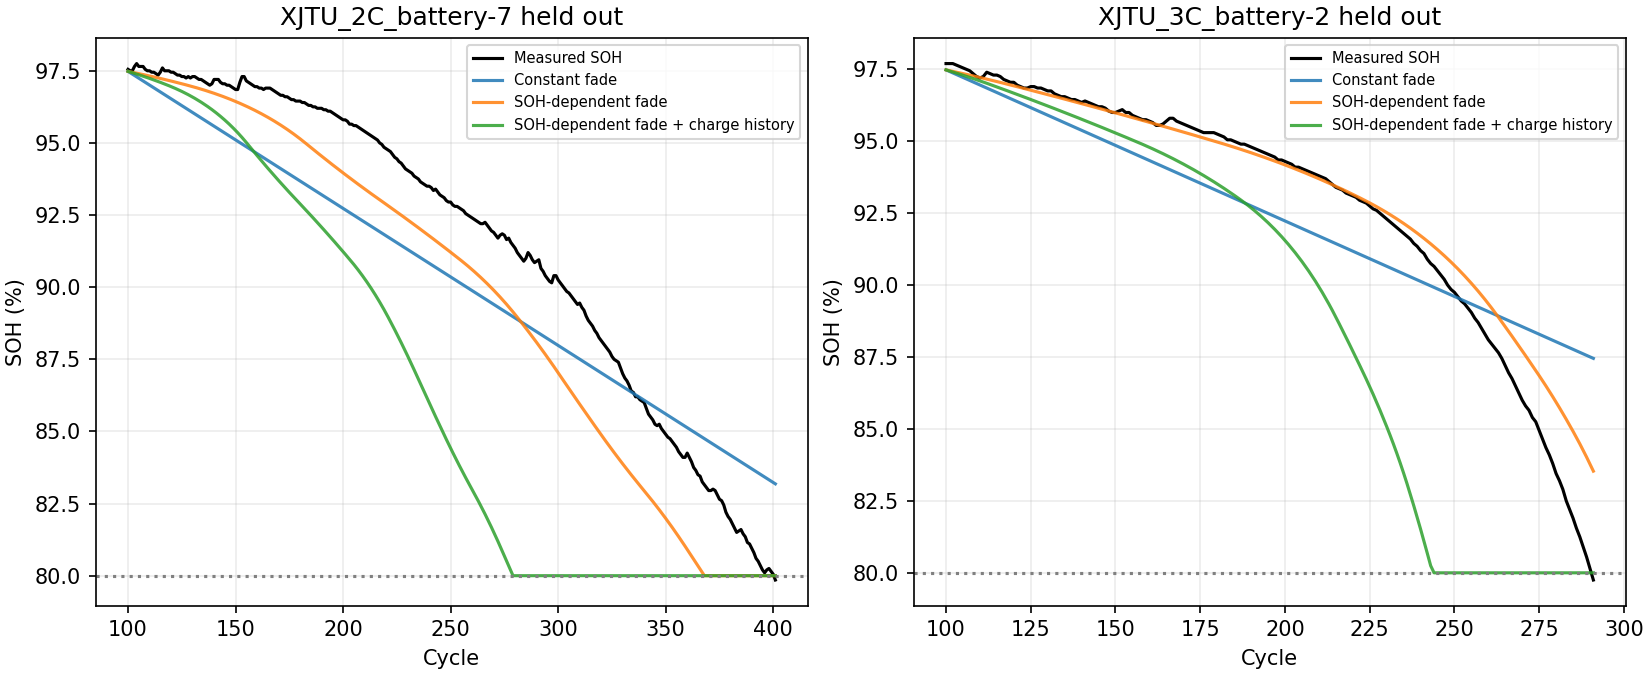

Download lifeguard_digital_twin_validation_results.zip from the notebook output.


In [91]:
check_guard_causality()
check_simulator()
soh_path = locate_soh_export(INPUT_ROOT)
label_path, rul_path = locate_auxiliary_files(INPUT_ROOT)
print(f"Reading cycle tables from {soh_path}")
cycles = load_cycles(soh_path)
eol = audit_eol(cycles, json.loads(label_path.read_text(encoding="utf-8")))
if not eol.event_status.isin(["observed", "right_censored"]).all():
    review = eol.loc[~eol.event_status.isin(["observed", "right_censored"]), ["cell_id", "event_status"]]
    raise ValueError(f"Review the EOL labels before running the simulation.\n{review.to_string(index=False)}")
pilots = eol.set_index("cell_id").loc[list(PILOT_EOLS)]
assert pilots.event_status.eq("observed").all() and pilots.observed_eol_cycle.to_dict() == PILOT_EOLS
splits, split_table = build_folds(cycles)
reference = load_rul_baseline(rul_path, eol, split_table)
with threadpool_limits(limits=1):
    trajectories, starts, calibration, charge_estimates = run_forecasts(cycles, eol, splits)
validate_forecasts(trajectories, starts, split_table)
points, horizon_metrics = score_trajectories(trajectories)
rul_detail, rul_metrics = score_rul(starts, reference)
decision, choices = select_at_100(rul_metrics, horizon_metrics)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
destination = OUTPUT_ROOT / "lifeguard_digital_twin_validation_results.zip"
config = {
    "dataset": "BatteryLife v12", "dataset_doi": "10.5281/zenodo.21149533", "soh_input": soh_path.name,
    "rul_reference_input": rul_path.name, "seed": SEED, "landmarks": list(LANDMARKS), "horizons": list(HORIZONS),
    "primary_landmark": PRIMARY_LANDMARK, "eol_soh_pct": EOL_SOH, "max_rollout_steps": MAX_STEPS,
    "bin_width_pp": BIN_WIDTH_PP, "max_rate_window": RATE_WINDOW_CYCLES, "min_rate_window": MIN_RATE_WINDOW,
    "min_cells_per_bin": MIN_CELLS_IN_BIN, "charge_history_window": HISTORY_WINDOW_CYCLES,
    "charge_history_endpoint_cycles": HISTORY_ENDPOINT_CYCLES, "charge_history_min_gap": HISTORY_MIN_GAP,
    "history_ratio_bounds": list(HISTORY_RATIO_BOUNDS), "history_shrinkage": HISTORY_SHRINKAGE,
    "chosen_rul_models_at_cycle_100": choices,
    "packages": {pkg: version(pkg) for pkg in ("numpy", "pandas", "scikit-learn", "matplotlib")},
}
with TemporaryDirectory(prefix="lifeguard_twin_validation_", dir=OUTPUT_ROOT) as directory:
    output = Path(directory) / "results"
    output.mkdir()
    for filename, table in (
        ("eol_audit.csv", eol), ("cell_splits.csv", split_table), ("transition_calibration.csv", calibration),
        ("charge_soh_estimates.csv", charge_estimates), ("rollout_starts.csv", starts),
        ("soh_trajectories.csv", trajectories), ("soh_horizon_predictions.csv", points),
        ("soh_horizon_metrics.csv", horizon_metrics), ("rul_predictions.csv", rul_detail),
        ("rul_metrics.csv", rul_metrics), ("prior_rul_reference.csv", reference), ("model_selection.csv", decision),
    ):
        table.to_csv(output / filename, index=False)
    (output / "run_config.json").write_text(json.dumps(config, indent=2) + "\n", encoding="utf-8")
    write_summary(output / "summary.md", eol, horizon_metrics, rul_metrics, choices, decision, starts)
    plot_examples(trajectories, output / "heldout_trajectories.png")
    package_results(output, destination)
    display(Markdown((output / "summary.md").read_text(encoding="utf-8")))
    display(Image(filename=str(output / "heldout_trajectories.png")))

print(f"Download {destination.name} from the notebook output.")